In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns


In [2]:
#Read in microglia unprocessed
script_loc = Path('clean_and_qc.ipynb').parent.resolve()
data_loc = script_loc.parent / "data/raw"
resources_loc = script_loc.parent / 'resources'

mdata = sc.read_h5ad(data_loc / "microglia_unprocessed.h5ad")

In [3]:
print(mdata.obs.columns)
mdata.obs.head()

Index(['orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability',
       'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region',
       'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin',
       'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid',
       'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx',
       'medications_atodc', 'tobacco_atod', 'manner_of_death',
       'cause_of_death', 'index_27', 'index_28', 'i7_index_seq',
       'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1'],
      dtype='str')


,orig_ident,scds_hybrid_score,scds_keep,miqc_probability,miqc_keep,dropletqc_nucfrac,dropletqc_keep,x,id,region,...,manner_of_death,cause_of_death,index_27,index_28,i7_index_seq,i5_index_seq,dsm_iv_oud,dsm_iv_aud,dsm_iv_cud,level1
AAACCCAAGTGCAGGT_1,LR_RM_C1034,0.124318,keep,0.016225,keep,0.803086,cell,21.0,C-1034,Caudate,...,Natural,Endocardial Fibroelastosis,SI-TT-B7,B7,GCCTTCGGTA,CCAACGATTT,0,1,0,CTL
AAACCCACACTAGGCC_1,LR_RM_C1034,0.082179,keep,0.018794,keep,0.758827,cell,21.0,C-1034,Caudate,...,Natural,Endocardial Fibroelastosis,SI-TT-B7,B7,GCCTTCGGTA,CCAACGATTT,0,1,0,CTL
AAACCCATCAAGCGTT_1,LR_RM_C1034,0.085345,keep,0.029884,keep,0.777698,cell,21.0,C-1034,Caudate,...,Natural,Endocardial Fibroelastosis,SI-TT-B7,B7,GCCTTCGGTA,CCAACGATTT,0,1,0,CTL
AAACGAAGTACCTTCC_1,LR_RM_C1034,0.019483,keep,0.031782,keep,0.705740,cell,21.0,C-1034,Caudate,...,Natural,Endocardial Fibroelastosis,SI-TT-B7,B7,GCCTTCGGTA,CCAACGATTT,0,1,0,CTL
AAACGAAGTCAGTCGC_1,LR_RM_C1034,0.041919,keep,0.014402,keep,0.789419,cell,21.0,C-1034,Caudate,...,Natural,Endocardial Fibroelastosis,SI-TT-B7,B7,GCCTTCGGTA,CCAACGATTT,0,1,0,CTL


In [4]:
mdata.var.head()

""
MIR1302-2HG
OR4F5
AL627309.1
AL627309.2
AL627309.5


In [5]:
#Annotate mitochondrial genes
mdata.var['mt'] = mdata.var.index.str.startswith('MT-')
mdata.var.head()

,mt
MIR1302-2HG,False
OR4F5,False
AL627309.1,False
AL627309.2,False
AL627309.5,False


In [6]:
#Incorporate ribosomal reads
ribo = pd.read_csv( resources_loc/ 'KEGG_RIBOSOME.v2026.2.Hs.txt', header=None)
mdata.var['ribo'] = mdata.var_names.isin(ribo[0].values)
mdata.var.head()


,mt,ribo
MIR1302-2HG,False,False
OR4F5,False,False
AL627309.1,False,False
AL627309.2,False,False
AL627309.5,False,False


In [7]:
mdata.raw.X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 15494253 stored elements and shape (6450, 31611)>

In [8]:
#Copy raw data into a regular anndata object
mdata_raw = mdata.raw.to_adata()
mdata_raw.var_names = mdata_raw.var['features'].values
mdata_raw

AnnData object with n_obs × n_vars = 6450 × 31611
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1'
    var: 'features'
    layers: None (.X)

In [9]:
#Keep only the gene names that actually exist in mdata_raw (to avoid dimension errors)
valid_vars = [name for name in mdata.var_names if name in mdata_raw.var_names]

#Slice the raw matrix data to the shared gene names only
aligned_raw_X = mdata_raw[:, valid_vars].X

#Making raw count a dedicated layer
mdata.layers['raw_counts'] = aligned_raw_X
mdata.layers['raw_counts']

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 15494224 stored elements and shape (6450, 31393)>

In [10]:
#Calculate standard qc metrics on mt and ribo
#This includes total counts, mean counts, etc.
(sc.pp.calculate_qc_metrics(mdata, layer="raw_counts", qc_vars=['mt', 'ribo'], 
                            percent_top=None, log1p=False, inplace=True))
mdata.obs.head()

,orig_ident,scds_hybrid_score,scds_keep,miqc_probability,miqc_keep,dropletqc_nucfrac,dropletqc_keep,x,id,region,...,dsm_iv_oud,dsm_iv_aud,dsm_iv_cud,level1,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
AAACCCAAGTGCAGGT_1,LR_RM_C1034,0.124318,keep,0.016225,keep,0.803086,cell,21.0,C-1034,Caudate,...,0,1,0,CTL,2850,6472.0,16.0,0.247219,22.0,0.339926
AAACCCACACTAGGCC_1,LR_RM_C1034,0.082179,keep,0.018794,keep,0.758827,cell,21.0,C-1034,Caudate,...,0,1,0,CTL,2266,4266.0,2.0,0.046882,20.0,0.468823
AAACCCATCAAGCGTT_1,LR_RM_C1034,0.085345,keep,0.029884,keep,0.777698,cell,21.0,C-1034,Caudate,...,0,1,0,CTL,2418,4638.0,17.0,0.366537,14.0,0.301854
AAACGAAGTACCTTCC_1,LR_RM_C1034,0.019483,keep,0.031782,keep,0.705740,cell,21.0,C-1034,Caudate,...,0,1,0,CTL,1252,1806.0,7.0,0.387597,20.0,1.107420
AAACGAAGTCAGTCGC_1,LR_RM_C1034,0.041919,keep,0.014402,keep,0.789419,cell,21.0,C-1034,Caudate,...,0,1,0,CTL,1835,3219.0,4.0,0.124262,10.0,0.310655


In [11]:
mdata.var.head()

,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
MIR1302-2HG,False,False,7,0.001085,99.891473,7.0
OR4F5,False,False,1,0.000155,99.984496,1.0
AL627309.1,False,False,343,0.058605,94.682171,378.0
AL627309.2,False,False,6,0.000930,99.906977,6.0
AL627309.5,False,False,1044,0.223101,83.813953,1439.0


C:\Users\chris\AppData\Local\Temp\ipykernel_23432\1901007008.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


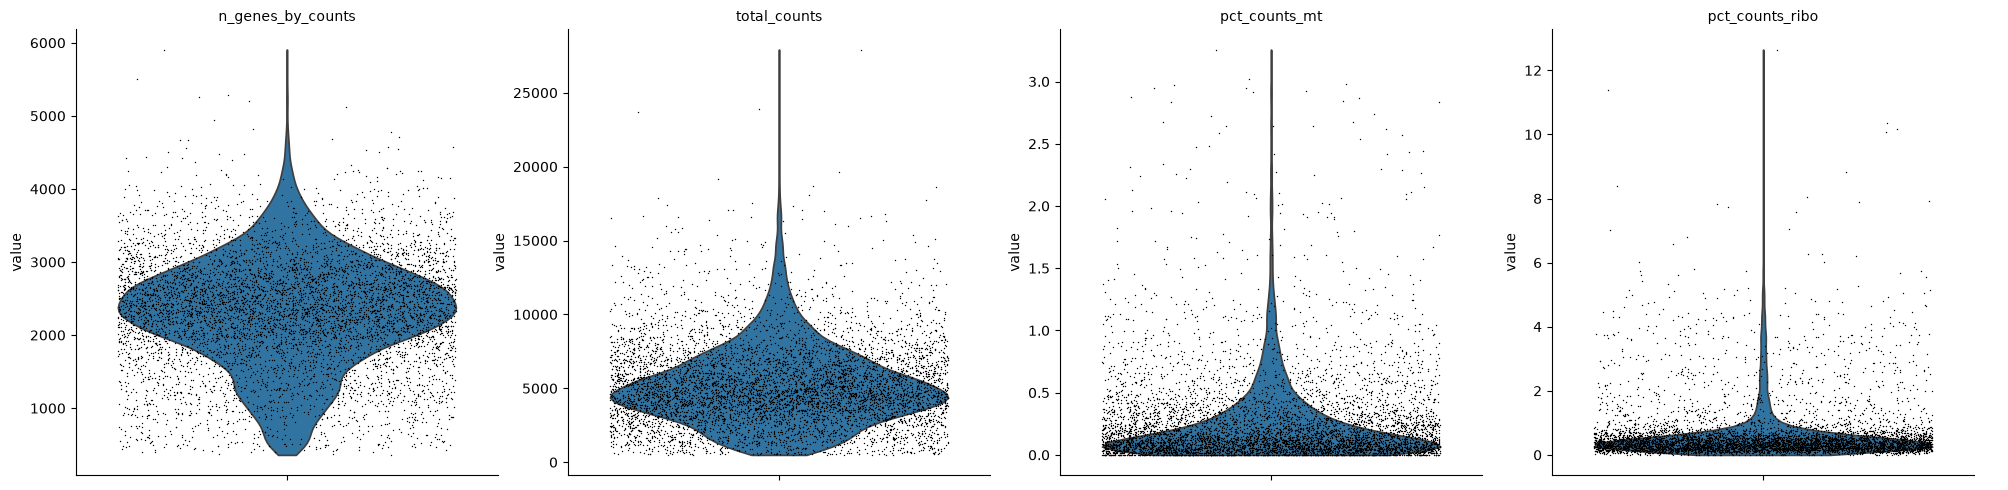

In [12]:
#Create and save violin plots for standard QC metrics
sc.pl.violin(
    mdata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt", 'pct_counts_ribo'],
    jitter=0.4,
    multi_panel=True,
    save='_qc.png'
)
 

C:\Users\chris\AppData\Local\Temp\ipykernel_23432\2797594528.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.scatter(mdata, "total_counts", "n_genes_by_counts", color="id", save='_bybatch_qc.png')


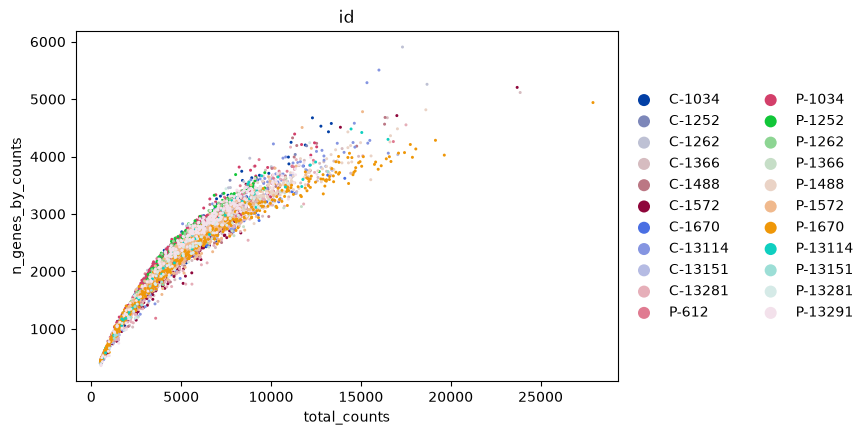

In [13]:
#Create and save scatter plot of n_genes_by_counts over total_counts mapping color to sample ID
sc.settings.figdir = script_loc.parent / 'outputs/qc_figures'

sc.pl.scatter(mdata, "total_counts", "n_genes_by_counts", color="id", save='_bybatch_qc.png')

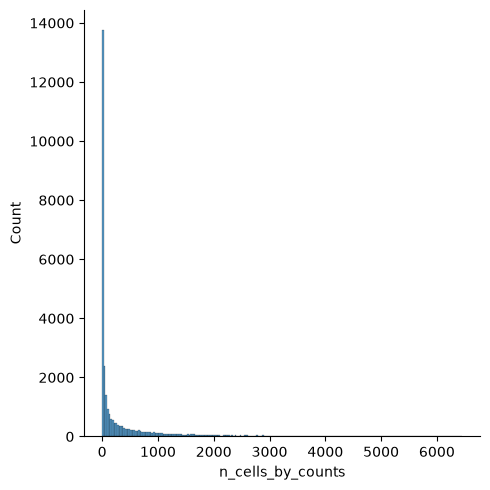

In [14]:
#Create and save histogram of cells per gene
(sns.displot(mdata.var, x='n_cells_by_counts')
 .savefig(script_loc.parent / 'outputs/qc_figures/pre_cell_by_gene.png', dpi=300))


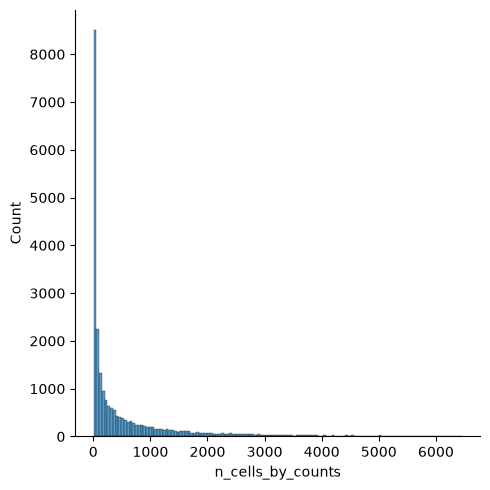

In [15]:
#Filter genes by n_cells_by_counts
sc.pp.filter_genes(mdata, min_cells=5)

#Create and save new histogram of cells per gene
(sns.displot(mdata.var, x='n_cells_by_counts')
 .savefig(script_loc.parent / 'outputs/qc_figures/post_cell_by_gene.png', dpi=300))

C:\Users\chris\AppData\Local\Temp\ipykernel_23432\3389306838.py:6: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


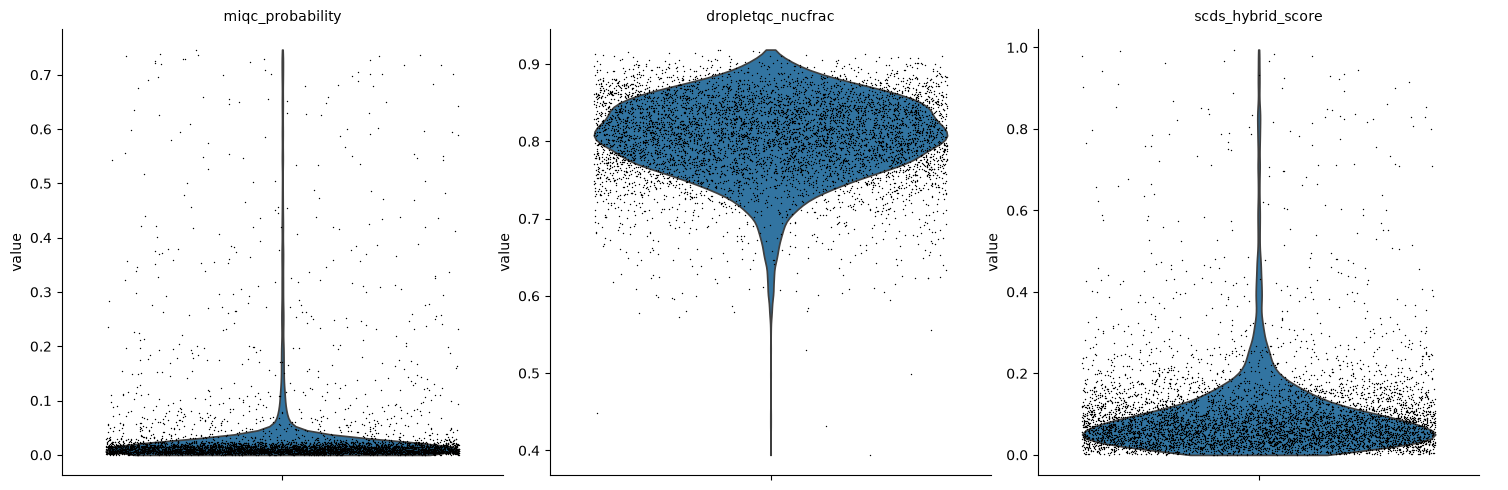

In [16]:
#Create and save violin plots for calculated QC metrics
#miQC used for identifying damaged nuclei
#DropletQC used for identifying empty droplets
#SCDS used for doublet detection

sc.pl.violin(
    mdata,
    ["miqc_probability", "dropletqc_nucfrac", "scds_hybrid_score"],
    jitter=0.4,
    multi_panel=True,
    save='_calc_qc.png'
)

In [17]:
print(mdata.obs.scds_keep.unique().tolist())
print(mdata.obs.miqc_keep.unique().tolist())
print(mdata.obs.dropletqc_keep.unique().tolist())

['keep']
['keep']
['cell']


In [18]:
#Insert raw_counts layer into the base
mdata.X = mdata.layers["raw_counts"].copy()

In [19]:
#Calculate doublet scores on dataset using scrublet
#Only allows <12 PCs probably because of HV cut-offs
sc.pp.scrublet(mdata, batch_key='orig_ident', n_prin_comps= 11)



C:\Users\chris\AppData\Local\Temp\ipykernel_23432\3851276659.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


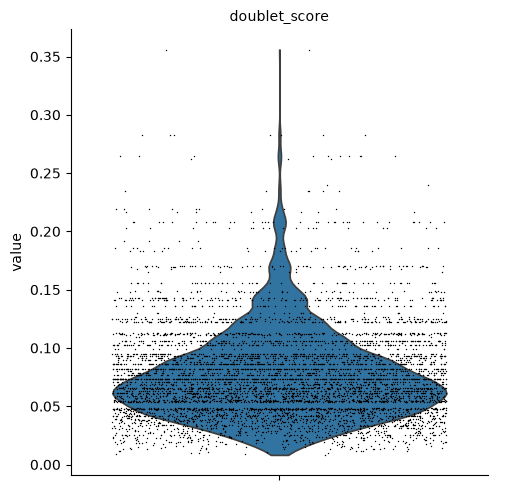

In [20]:

sc.pl.violin(
    mdata,
    ["doublet_score"],
    jitter=0.4,
    multi_panel=True,
    save="_doublet.png")

In [21]:
mdata

AnnData object with n_obs × n_vars = 6450 × 24087
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'level1', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'id_colors', 'scrublet'
    layers: None (.X), 'raw_counts'

In [22]:
len(mdata[mdata.obs['predicted_doublet']==1])

245

In [23]:
#Normalize to CP10k, create a new layer
mdata.layers["CP10k_counts"] = mdata.X.copy()
sc.pp.normalize_total(mdata, target_sum=1e4, layer='CP10k_counts')
sc.pp.log1p(mdata, layer='CP10k_counts')


In [24]:
#Write mdata to data/intermediate
mdata.write_h5ad(script_loc.parent / 'data/intermediate/microglia_preprocessed.h5ad')